In [7]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from datetime import date
import re
from tqdm import tqdm
import time
from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore
from scipy.spatial.distance import jaccard
import itertools

today = date.today()

# Get Distributions

**STRING Associations**

In [2]:
protein_assoc_sub = pd.read_pickle('../data/hg19-protein-associations.pkl')
protein_assoc_sub

,protein2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,,,,,,,
9606.ENSP00000000233,9606.ENSP00000379496,0,0,0,0,0,0,54,0,0,0,0,103,85,155,ARF5,PDE1C
9606.ENSP00000000233,9606.ENSP00000314067,0,0,0,0,0,0,0,0,180,0,0,0,61,197,ARF5,PAK2
9606.ENSP00000000233,9606.ENSP00000263116,0,0,0,0,0,0,62,0,152,0,0,0,101,222,ARF5,RAB36
9606.ENSP00000000233,9606.ENSP00000361263,0,0,0,0,0,0,0,0,161,0,0,47,58,181,ARF5,RAPGEF1
9606.ENSP00000000233,9606.ENSP00000409666,0,0,0,0,0,60,63,0,213,0,0,0,72,270,ARF5,SUMO3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000485678,9606.ENSP00000321447,0,0,0,0,888,214,49,0,0,0,0,0,0,220,OR6Q1,OR4S1
9606.ENSP00000485678,9606.ENSP00000308270,0,0,0,0,899,152,0,0,0,0,0,0,0,151,OR6Q1,OR5B3
9606.ENSP00000485678,9606.ENSP00000335660,0,0,0,0,0,182,0,0,0,0,0,0,0,181,OR6Q1,KRTAP19-2


In [3]:
protein_list = list(set(protein_assoc_sub.protein1_pref.tolist()+protein_assoc_sub.protein2_pref.tolist()))
print(len(protein_list))

18071


In [4]:
numzeros = np.zeros(18071**2 - len(protein_assoc_sub))
zerodistr = np.append(numzeros, protein_assoc_sub.combined_score.to_numpy(), axis=0)
distr = protein_assoc_sub.combined_score.to_numpy()

In [17]:
distr

array([  0.,   0.,   0., ..., 181., 154., 167.])

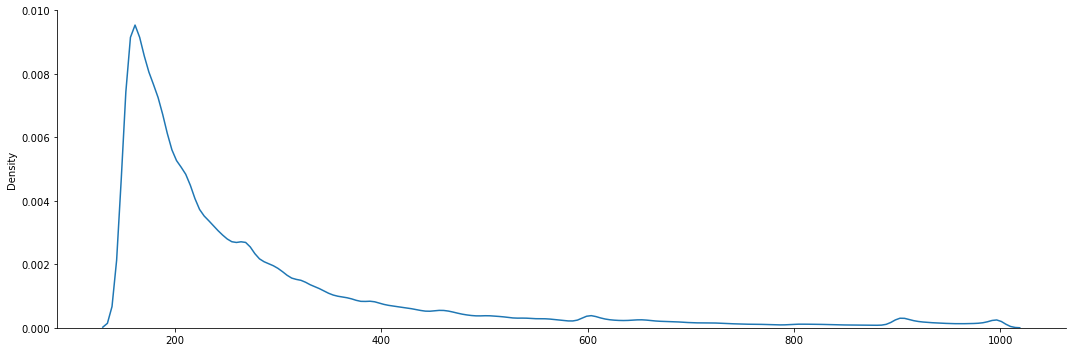

In [8]:
sns.displot(distr, kind = 'kde', height=5, aspect=3)

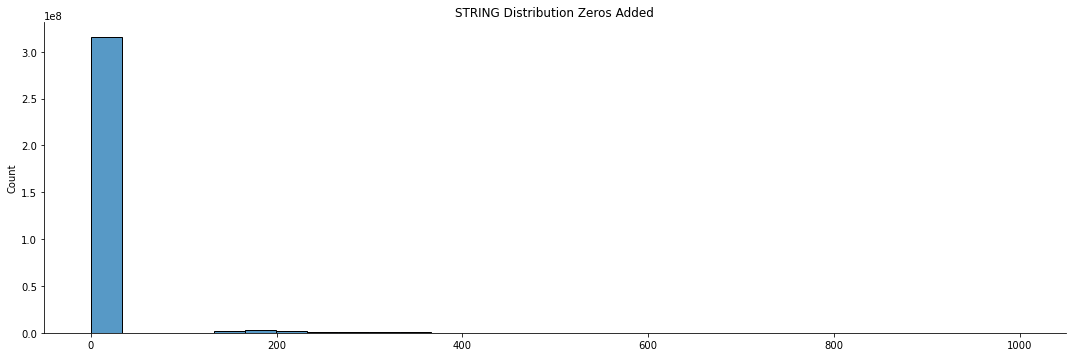

In [32]:
distr_plot = sns.displot(distr, height=5, aspect=3)
distr_plot.set(title='STRING Distribution Zeros Added')

In [35]:
percentileofscore(zerodistr, 150)

96.67423876812053

In [43]:
percentileofscore(distr, 750)

96.4729943720952

In [14]:
gata1 = pd.read_pickle('../data/GATA1_top-STRING-associations.pkl')
gata1['combined_score'][:100]

protein1
9606.ENSP00000365858    999
9606.ENSP00000365858    999
9606.ENSP00000365858    999
9606.ENSP00000365858    996
9606.ENSP00000365858    996
                       ... 
9606.ENSP00000365858    671
9606.ENSP00000365858    658
9606.ENSP00000365858    658
9606.ENSP00000365858    657
9606.ENSP00000365858    643
Name: combined_score, Length: 100, dtype: int64

In [19]:
percentileofscore(zerodistr, 643)

99.81807428767965

**DHS distribution**

In [9]:
dhs_df = pd.read_pickle('../data/data_240.pkl')
dhs_df

,DS10018,DS10060,DS10518,DS10666,DS11872,DS11909,DS11939,DS12274,DS12352,DS12357,...,DS55945A,DS55923A,DS39148B,DS39417A,DS23388A,DS24714A,DS24801A,DS24814A,DS36206B,DS37716C
identifier,,,,,,,,,,,,,,,,,,,,,
1.10011,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.10021,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.10025,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.10027,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.1003,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.994281,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Y.994286,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Y.994292,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [2]:
dhs_metadata_df = pd.read_pickle('../data/dhs_metadata.pkl')
dhs_metadata_df

,seqname,start,end,mean_signal,numsamples,summit,core_start,core_end,component
identifier,,,,,,,,,
1.10011,chr1,16140,16200,0.129388,1,16170,16170.0,16170.0,Tissue invariant
1.10021,chr1,51868,52040,0.080034,1,51970,51970.0,51970.0,Placental / trophoblast
1.10025,chr1,57280,57354,0.273251,4,57350,57350.0,57350.0,Neural
1.10027,chr1,66370,66482,0.183716,8,66430,66410.0,66430.0,Primitive / embryonic
1.1003,chr1,79100,79231,0.113049,2,79150,79150.0,79150.0,Placental / trophoblast
...,...,...,...,...,...,...,...,...,...
Y.994281,chrY,56882540,56882719,0.038079,1,56882610,56882610.0,56882610.0,Lymphoid
Y.994286,chrY,56882864,56882980,0.115489,1,56882930,56882930.0,56882930.0,Lymphoid
Y.994292,chrY,56883733,56883960,0.491377,5,56883830,56883742.0,56883870.0,Placental / trophoblast


In [10]:
# file = open('../output/dhs-jaccard-240s-scores-every-100.pkl','r')
with open('../output/dhs-jaccard-240s-scores-every-100.pkl', "rb") as input_file:
    dhs_scores = pickle.load(input_file)

In [11]:
dhs_scores_list = list(itertools.chain.from_iterable(dhs_scores))
dhs_scores_list

[1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.0,
 1.0,
 1.0,
 1.0,
 0.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.0,
 0.0,
 1.0,
 1.0,
 1.0,
 0.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.0,
 0.0,
 0.0,
 1.0,
 1.0,
 1.0,
 0.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.9090909090909091,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.9090909090909091,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.7857142857142857,
 0.9230769230769231,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0

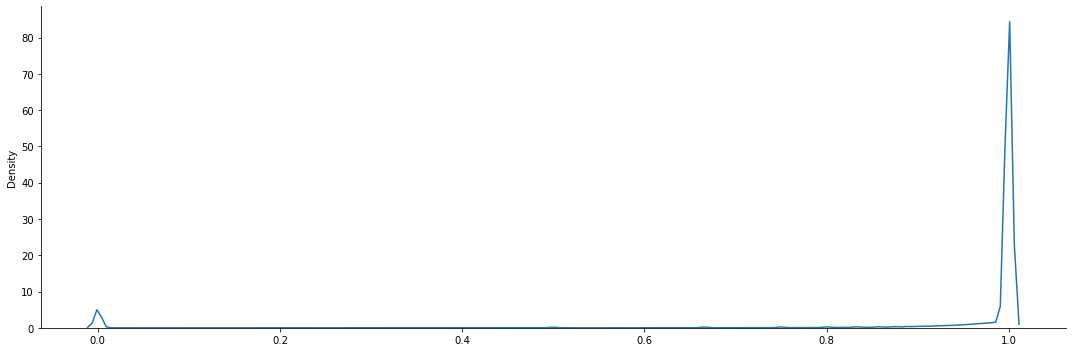

In [12]:
sns.displot(dhs_scores_list, kind='kde', height=5, aspect=3)

In [28]:
dhs_df = pd.read_pickle('../data/data_240.pkl')

dhs_arr = dhs_df.to_numpy()

dhs_arr[1]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [8]:
hg38_dhs_ranges = dict()

hg38_chromosomes = {
    'chr1': 248956422,
    'chr2': 242193529,
    'chr3': 198295559,
    'chr4': 190214555,
    'chr5': 181538259,
    'chr6': 170805979,
    'chr7': 159345973,
    'chr8': 145138636,
    'chr9': 138394717,
    'chr10': 133797422,
    'chr11': 135086622,
    'chr12': 133275309,
    'chr13': 114364328,
    'chr14': 107043718,
    'chr15': 101991189,
    'chr16': 90338345,
    'chr17': 83257441,
    'chr18': 80373285,
    'chr19': 58617616,
    'chr20': 64444167,
    'chr21': 46709983,
    'chr22': 50818468,
    'chrX': 156040895,
    'chrY': 57227415
}

# for chrm in hg38_chromosomes.keys():
#     chrm_dhs = dhs_metadata_df[dhs_metadata_df['seqname'] == chrm].sort_values(by='start')
#     start = 0
#     chrm_dict = {}
#     for i in range(1, len(chrm_dhs)):
#         dhs1 = chrm_dhs.iloc[i-1, :]
#         dhs2 = chrm_dhs.iloc[i, :]
        
#         diff = (dhs2.start - dhs1.end)//2

#         try:
#             chrm_dict[(start, dhs1.end+diff)] = dhs1.name
#         except:
#             print((start, dhs1.end+diff))
#             print(dhs1.name)
#         start = dhs2.start - diff
    
#     chrm_dict[(start, hg38_chromosomes[chrm])] = dhs2.name
#     hg38_dhs_ranges[chrm] = chrm_dict
    
# hg38_dhs_ranges



# hg38_dhs_ranges_every100 = dict()

# for chrm in hg38_chromosomes.keys():
#     chrm_dhs = dhs_metadata_df[dhs_metadata_df['seqname'] == chrm].sort_values(by='start')
#     start = 0
#     chrm_dict = {}
#     for i in range(100, len(chrm_dhs), 100):
#         dhs1 = chrm_dhs.iloc[i-100, :]
#         dhs2 = chrm_dhs.iloc[i, :]
        
#         diff = (dhs2.start - dhs1.end)//2
#         chrm_dict[(start, dhs1.end+diff)] = dhs1.name
#         start = dhs2.start - diff
    
#     chrm_dict[(start, hg38_chromosomes[chrm])] = dhs2.name
#     hg38_dhs_ranges_every100[chrm] = chrm_dict
    
# hg38_dhs_ranges_every100

In [53]:
similar_dhs_indices = np.where(dhs_scores[-1] == 0)[0]
print(similar_dhs_indices)

[   21    26    28 ... 35908 35909 35913]


In [54]:
dhs_sub = dhs_metadata_df.iloc[similar_dhs_indices*100, :]

In [55]:
dhs_df.loc[dhs_sub.index]

,DS10018,DS10060,DS10518,DS10666,DS11872,DS11909,DS11939,DS12274,DS12352,DS12357,...,DS55945A,DS55923A,DS39148B,DS39417A,DS23388A,DS24714A,DS24801A,DS24814A,DS36206B,DS37716C
identifier,,,,,,,,,,,,,,,,,,,,,
1.1060685,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.10699,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1.107253,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.108588,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.1100776,0,0,0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.407189,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Y.41006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Y.41326,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [56]:
print(len(dhs_scores[-1]))

35918


In [57]:
print(dhs_df.loc[dhs_sub.index].sum(axis=1))

identifier
1.1060685     2
1.10699       6
1.107253      1
1.108588      1
1.1100776     4
             ..
Y.407189      1
Y.41006       0
Y.41326       0
Y.42083       0
Y.433077     22
Length: 7845, dtype: int64


In [42]:
dhs_df.to_numpy().shape

(3591898, 240)

In [44]:
len(dhs_df.to_numpy()[0])

240

In [58]:
len(dhs_scores[-1])

35918

In [8]:
percentileofscore(dhs_scores_list, 0)

2.455230311596232

In [9]:
percentileofscore(dhs_scores_list, 0.69)

5.519243179137332

**GWAS ENRICHMENT**

In [13]:
gwas_enrich = pd.read_csv('../data/100010.hg38.bed', delimiter='\t', header=None)

gwas_enrich = gwas_enrich.set_axis(['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'], axis=1, inplace=False)

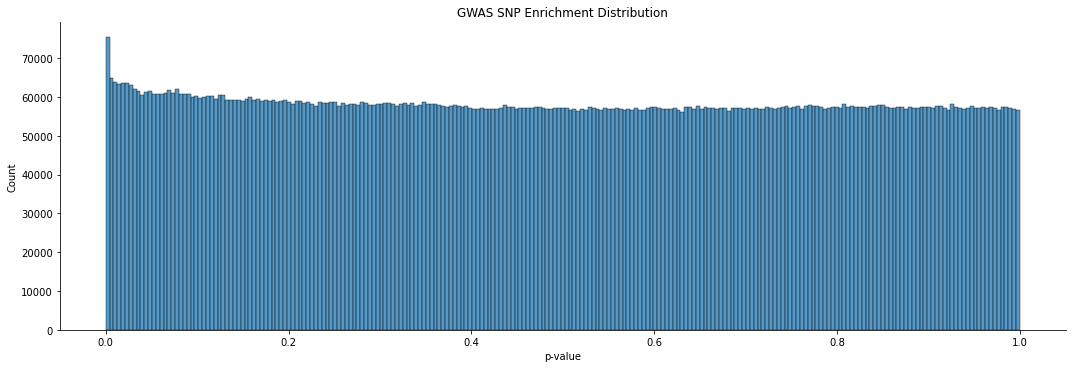

In [15]:
gwas_distr_plot = sns.displot(gwas_enrich['p-value'], height=5, aspect=3)
gwas_distr_plot.set(title='GWAS SNP Enrichment Distribution')

**Epilogos**

# Get Combined Score

In [9]:
def process_bedfile(assembly):
    ## READ IN BED FILE WITH COORDINATES
    
    if assembly == 'hg19':
        gene_df = pd.read_csv('../data/hg19.gencode.v19.annotation.hgnc.longest.gtf.bed14',
                      delimiter='\t', header = None, index_col=3)
    elif assembly == 'hg38':
        gene_df = pd.read_csv('../data/hg38.gencode.v38.annotation.gtf.genePred.hgnc.longest.noChrM.bed',
                      delimiter='\t', header = None, index_col=3)
    
    genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-' + assembly + '.pkl')
    
    gene_df = gene_df.rename({3:'gene_names', 0:'chr', 1:'start', 2:'end', 5:'strand', 9:'descriptor'}, axis=1)
    gene_df.index = gene_df.index.rename('gene_names')
    
    # Remove duplicate genes
    gene_df_no_dupes = gene_df[~gene_df.index.duplicated(keep='first')]
    print(gene_df_no_dupes.shape, gene_df.shape)

    # Remove duplicate genes from 'genes_in_both'
    genes_in_both_df = gene_df_no_dupes.loc[genes_in_both.preferred_name.tolist()].reset_index()
    genes_in_both_dup_removed = genes_in_both_df.drop_duplicates(subset=['gene_names'])
    print(genes_in_both_df.shape, genes_in_both_dup_removed.shape)
    genes_in_both_dup_removed.set_index('gene_names', inplace=True)
    return genes_in_both_dup_removed

In [14]:
protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
protein_assoc_sub

,protein2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,,,,,,,
9606.ENSP00000000233,9606.ENSP00000379496,0,0,0,0,0,0,54,0,0,0,0,103,85,155,ARF5,PDE1C
9606.ENSP00000000233,9606.ENSP00000314067,0,0,0,0,0,0,0,0,180,0,0,0,61,197,ARF5,PAK2
9606.ENSP00000000233,9606.ENSP00000263116,0,0,0,0,0,0,62,0,152,0,0,0,101,222,ARF5,RAB36
9606.ENSP00000000233,9606.ENSP00000361263,0,0,0,0,0,0,0,0,161,0,0,47,58,181,ARF5,RAPGEF1
9606.ENSP00000000233,9606.ENSP00000409666,0,0,0,0,0,60,63,0,213,0,0,0,72,270,ARF5,SUMO3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000485678,9606.ENSP00000354800,0,0,0,0,872,213,0,0,0,0,0,0,0,213,OR6Q1,OR5D13
9606.ENSP00000485678,9606.ENSP00000308270,0,0,0,0,899,152,0,0,0,0,0,0,0,151,OR6Q1,OR5B3
9606.ENSP00000485678,9606.ENSP00000335660,0,0,0,0,0,182,0,0,0,0,0,0,0,181,OR6Q1,KRTAP19-2


In [18]:
hg38_proc_gene_df = process_bedfile('hg38')
hg38_proc_gene_df.iloc[:5, :]

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


,chr,start,end,4,strand,6,7,8,descriptor,10,11,12,13
gene_names,,,,,,,,,,,,,
ARF5,chr7,127588385,127591681,8,+,ENST00000463733,658,protein-coding,ADP ribosylation factor 5,127591681,127591681,"127588385,127589082,127589484,127590962,127591...","127588565,127589163,127590137,127591088,127591..."
M6PR,chr12,8940363,8949761,21,-,ENST00000536844,6752,protein-coding,"mannose-6-phosphate receptor, cation dependent",8941817,8946404,"8940363,8943800,8945417,8946228,8949487,","8941940,8943910,8945584,8946405,8949761,"
FKBP4,chr12,2794969,2805423,53,+,ENST00000001008,3720,protein-coding,FKBP prolyl isomerase 4,2795139,2803258,"2794969,2797137,2797728,2798705,2799087,279984...","2795244,2797282,2797871,2798826,2799244,279994..."
CYP26B1,chr2,72129237,72147862,29,-,ENST00000001146,20581,protein-coding,cytochrome P450 family 26 subfamily B member 1,72132226,72147834,"72129237,72133022,72134760,72135143,72143988,7...","72132619,72133307,72134916,72135419,72144213,7..."
NDUFAF7,chr2,37231657,37249160,5,+,ENST00000002125,28816,protein-coding,NADH:ubiquinone oxidoreductase complex assembl...,37231705,37248350,"37231657,37232105,37236095,37237756,37241577,3...","37231760,37232266,37236176,37237867,37241791,3..."


In [22]:
GATA1_bed_info = hg38_proc_gene_df[hg38_proc_gene_df.index == 'GATA1']
GATA1_bed_info

,chr,start,end,4,strand,6,7,8,descriptor,10,11,12,13
gene_names,,,,,,,,,,,,,
GATA1,chrX,48786572,48794311,233,+,ENST00000376665,4170,protein-coding,GATA binding protein 1,48791109,48794268,"48786572,48791090,48791843,48792322,48793171,4...","48786645,48791329,48792221,48792468,48793297,4..."


In [23]:
## Upstream of GATA1
GATA1_up_coord_1 = 'chrX 48786500'
GATA1_up_coord_2 = 'chrX 48782500'

In [11]:
# Go through each category to find closest object

# STRING
hg38_gene_ranges_fn = open('../data/hg38_gene_ranges.pkl', "rb")
hg38_gene_ranges = pickle.load(hg38_gene_ranges_fn)

# def findWithinRegion_gene(start, stop):
    

def findNearestGene(coord, gene_ranges):    
    # Subset genes_df to just same chromosome
    coord = coord.split(' ')
    chrm = coord[0]
    coord = int(coord[1])
    
    chrm_range = gene_ranges[chrm]
    chrm_range_list = list(chrm_range)
    
    for i, interval in enumerate(chrm_range_list):
        if coord in range(interval[0], interval[1]):
            return chrm_range[interval]
        
# DHS
def findNearestDHS(coord):
    coord = coord.split(' ')
    chrm = coord[0]
    coord = int(coord[1])
    
    dhs_metadata_df = pd.read_pickle('../data/dhs_metadata.pkl')
    dhs_metadata_sub = dhs_metadata_df[dhs_metadata_df['seqname'] == chrm]

    return dhs_metadata_sub.loc[(dhs_metadata_sub['start'] < coord) & (dhs_metadata_sub['end'] > coord)]

def getDHSRecommendations(closest_dhs):
    dhs_df = pd.read_pickle('../data/data_240.pkl')

    dhs_arr = dhs_df.to_numpy()
    
    closest_dhs_index = dhs_df.index.tolist().index(closest_dhs)

    dist = []

    for i, row in enumerate(dhs_df.index.tolist()): 
        dist.append(jaccard(dhs_arr[closest_dhs_index], dhs_arr[i]))
    dist_df = pd.Series(dist, index=dhs_df.index)
    dist_sorted = dist_df.sort_values()
#     dist_0 = dist_sorted[dist_sorted==0]

    dhs_recommendations = dist_sorted[:50]
    
    dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')
    dhs_recommendations.name = 'percentile'
    dhs_recommendations = pd.concat([dhs_metadata.loc[dhs_recommendations.index], dhs_recommendations], axis=1)

    return dhs_recommendations
    
def getGeneAssociations(closest_gene):
    hg38_protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
    hg38_gene_df = process_bedfile('hg38')
    
    specific_gene_df = hg38_protein_assoc_sub[hg38_protein_assoc_sub['protein1_pref'] == closest_gene].sort_values('combined_score', ascending=False)

    specific_gene_info = hg38_gene_df.loc[specific_gene_df['protein2_pref'].tolist()].reset_index()
    specific_gene_info = specific_gene_info.drop_duplicates('gene_names')
    

    gene_insert = hg38_gene_df.loc[closest_gene]
    gene_insert['gene_names'] = closest_gene

    # Keep this line when commenting out the closest gene itself.
    specific_gene_info['combined_score'] = specific_gene_df['combined_score'].tolist()
    specific_gene_info = specific_gene_info.append(gene_insert)

    idx = [-1] + [i for i in range(len(specific_gene_info)-1)]
    specific_gene_info = specific_gene_info.reset_index().iloc[idx]


    specific_gene_info = specific_gene_info[['chr', 'start', 'end', 'gene_names', 'combined_score', 'descriptor']]
    return specific_gene_info[:50]


def getRecommendations(coord):
    closest_gene = findNearestGene(coord, hg38_gene_ranges)
    closest_dhs = findNearestDHS(coord)
    
    gene_associations = getGeneAssociations(closest_gene)
    dhs_recommendations = getDHSRecommendations(closest_dhs)
    
    with open('../output/dhs-jaccard-240s-scores-every-100.pkl', "rb") as input_file:
        dhs_scores = pickle.load(input_file)
    dhs_scores_list = list(itertools.chain.from_iterable(dhs_scores))
    
    recommendations_df = gene_associations['combined_score']
    
def percentileofscore_gene(score):
    protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
    distr = protein_assoc_sub.combined_score.to_numpy()
    
    return percentileofscore(distr, score)

def percentileofscore_dhs(score):
    with open('../output/dhs-jaccard-240s-scores-every-100.pkl', "rb") as input_file:
        dhs_scores = pickle.load(input_file)
    distr = list(itertools.chain.from_iterable(dhs_scores))
    return 100-percentileofscore(distr, score)

def percentileofscore_snp(score):
    snp_df = pd.read_pickle('../output/CT-GWAS-SNP-bed.pkl')
    distr = snp_df(snp_df['p-value'].tolist())
    return 100-percentileofscore(distr, score) 
    

In [69]:
np.save('../output/chr1-48786500.npy', dist)

In [140]:
closest_gene = findNearestGene(GATA1_up_coord_1, hg38_gene_ranges)
closest_dhs = findNearestDHS(GATA1_up_coord_1).index[0]

print(closest_gene)
print(closest_dhs)

gene_associations = getGeneAssociations(closest_gene)
dhs_recommendations = getDHSRecommendations(closest_dhs)


closest_gene2 = findNearestGene(GATA1_up_coord_2, hg38_gene_ranges)
closest_dhs2 = findNearestDHS(GATA1_up_coord_2).index[0]

print(closest_gene2)
print(closest_dhs2)

gene_associations2 = getGeneAssociations(closest_gene2)
dhs_recommendations2 = getDHSRecommendations(closest_dhs2)


GATA1
X.381393
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


GATA1
X.381372
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


In [ ]:
gene_associations['scaled_score'] = gene_associations['combined_score'].map(percentileofscore_gene)
# gene_associations

dhs_scaled_score = dhs_recommendations.map(percentileofscore_dhs)

gene_associations2['scaled_score'] = gene_associations2['combined_score'].map(percentileofscore_gene2)
# gene_associations

dhs_scaled_score2 = dhs_recommendations2.map(percentileofscore_dhs2)

In [111]:
# gene_associations = gene_associations.set_index('gene_names')
print(gene_associations.columns)
gene_associations.loc[['chr', 'start', 'end']]


recommendations_df = pd.concat([gene_associations['scaled_score'], dhs_scaled_score], axis=0)
# scores_df = pd.concat([gene_associations['chr', 'start', 'end']])

recommendations_df

Index(['chr', 'start', 'end', 'combined_score', 'descriptor', 'scaled_score'], dtype='object')


GATA1              NaN
TAL1         99.908778
ZFPM1        99.908778
LMO2         99.908778
BRD3         99.731293
LDB1         99.731293
SPI1         99.705196
EP300        99.681009
TCF3         99.602423
LDB2         99.566716
BCL11A       99.490484
MYB          99.490484
HDAC5        99.447364
HDAC1        99.447364
ZFPM2        99.377193
ITGA2B       99.284845
AHSP         99.258202
RBBP4        99.232532
HBB          99.155985
KLF1         99.117739
NFE2         99.067019
HEY1         99.040515
GP1BA        99.026651
HDAC4        99.013038
HDAC2        98.972012
CHD4         98.928039
HDAC3        98.882797
SMARCA4      98.689918
MTA2         98.654684
RBBP7        98.618709
GATAD2B      98.524953
GFI1B        98.524953
GATAD2A      98.504333
CHD3         98.504333
MBD3         98.504333
HES1         98.461426
THBS1        98.393117
RUNX1        98.393117
AGO1         98.291845
AGO3         98.291845
AGO4         98.291845
CCNH         98.262579
ALAS2        98.262579
MNAT1      

In [131]:
print(closest_dhs)
dhs_recommendations = getDHSRecommendations(closest_dhs)

dhs_scaled_score = dhs_recommendations.map(percentileofscore_dhs)

dhs_coords = dhs_metadata_df.loc[dhs_scaled_score.index][['seqname', 'start', 'end']]

dhs_coords['dhs_percentile'] = dhs_scaled_score
dhs_coords

X.381393


,seqname,start,end,dhs_scores
identifier,,,,
1.525079,chr1,117614006,117614217,97.544770
3.748713,chr3,142929940,142930180,97.544770
5.576179,chr5,96043480,96043700,97.544770
7.940878,chr7,148903560,148903800,97.544770
3.981659,chr3,194254280,194254461,97.544770
...,...,...,...,...
7.881156,chr7,138314370,138314613,95.087962
11.482211,chr11,57353120,57353360,95.087962
8.336705,chr8,38165720,38165920,95.087962


In [136]:
dhs_coords = dhs_coords.rename(columns = {'dhs_scores':'dhs_percentile'})
dhs_coords[:10]

,seqname,start,end,dhs_percentile
identifier,,,,
1.5250789,chr1,117614006,117614217,97.544770
3.748713,chr3,142929940,142930180,97.544770
5.576179,chr5,96043480,96043700,97.544770
7.940878,chr7,148903560,148903800,97.544770
3.981659,chr3,194254280,194254461,97.544770
X.381393,chrX,48786380,48786620,97.544770
9.8094964,chr9,109123080,109123300,95.088071
16.763175,chr16,66572460,66572690,95.088071
5.244274,chr5,29089760,29090069,95.088071


# GWAS SNP associations

In [122]:
col_names = ['seqname', 'start', 'end', 'Reference SNP cluster ID', 'p-value', 'trait phenotype']

snp_df = pd.read_csv('../data/UKBB_all_traits_all_sig_associations_CT20220207.bed', names=col_names, header=None, delimiter='\t')

snp_df.to_pickle('../output/CT-GWAS-SNP-bed.pkl')

snp_df

,seqname,start,end,Reference SNP cluster ID,p-value,trait phenotype
0,chr12,130300801,130300802,rs73150827,3.555020e-08,100022
1,chr4,99318162,99318163,rs1229984,1.041850e-13,100022
2,chr9,8303561,8303562,rs112120933,3.689310e-09,100022
3,chr1,46941503,46941504,rs141586057,4.034800e-08,1001
4,chr20,52932649,52932650,rs185961463,1.629800e-08,1001
...,...,...,...,...,...,...
11252644,chr5,32713221,32713222,rs3828589,1.778290e-08,93_irnt
11252645,chr5,32713730,32713731,rs3792765,1.673070e-08,93_irnt
11252646,chr5,32714164,32714165,rs1421811,1.879810e-08,93_irnt
11252647,chr5,32716368,32716369,rs34628434,1.116850e-08,93_irnt


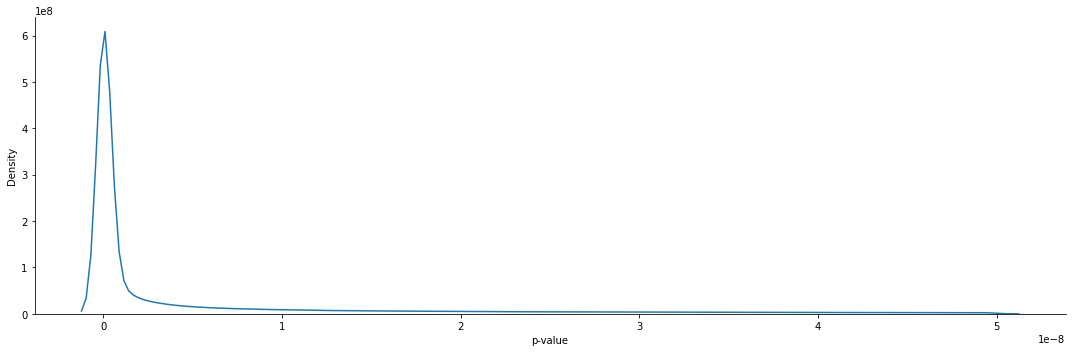

In [120]:
sns.displot(snp_df['p-value'], kind = 'kde', height=5, aspect=3)

# Score Fusion

GATA1 region (start: -5000 + 1000)

In [33]:
start = 'chrX 48781572'
end = 'chrX 48787572'

hg38_gene_ranges_fn = open('../data/hg38_gene_ranges.pkl', "rb")
hg38_gene_ranges = pickle.load(hg38_gene_ranges_fn)

In [34]:
dhs_list = findNearestDHS(start)
gene_list = findNearestGene(start, hg38_gene_ranges)
print(dhs_list)
print(gene_list)

Empty DataFrame
Columns: [seqname, start, end, mean_signal, numsamples, summit, core_start, core_end, component]
Index: []
GATA1


In [35]:
print(dhs_list.index[0])
dhs_recommendations = getDHSRecommendations(dhs_list.index[0])

dhs_recommendations

IndexError: index 0 is out of bounds for axis 0 with size 0

In [36]:
gene_associations = getGeneAssociations(gene_list)
gene_associations

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


,chr,start,end,gene_names,combined_score,descriptor
1728,chrX,48786572,48794311,GATA1,NaN,GATA binding protein 1
0,chr1,47216289,47231715,TAL1,999.0,"TAL bHLH transcription factor 1, erythroid dif..."
1,chr16,88453279,88537031,ZFPM1,999.0,"zinc finger protein, FOG family member 1"
2,chr11,33858575,33892076,LMO2,999.0,LIM domain only 2
3,chr9,134030304,134068026,BRD3,996.0,bromodomain containing 3
4,chr10,102106488,102120368,LDB1,996.0,LIM domain binding 1
5,chr11,47354859,47378547,SPI1,995.0,Spi-1 proto-oncogene
6,chr22,41092591,41180077,EP300,994.0,E1A binding protein p300
7,chr19,1609291,1652615,TCF3,990.0,transcription factor 3
8,chr4,16501540,16898645,LDB2,988.0,LIM domain binding 2


In [45]:
# Take those in the same chromosome and see if they match any other dhs or gene
# ChrX has a region within 200 bp of each other if you include GATA1
for chrm in hg38_chromosomes.keys():
    if chrm == 'chrY':
        chrm_genes = gene_associations[gene_associations['chr'] == chrm]
        chrm_dhs = dhs_recommendations[dhs_recommendations['seqname'] == chrm]
        print(chrm_genes)
        print(chrm_dhs)
        dhs_starts = chrm_dhs['start'].tolist()
        genes_starts = chrm_genes['start'].tolist()
        dhs_ends = chrm_dhs['end'].tolist()
        genes_ends = chrm_genes['end'].tolist()
#     for dhs in dhs_starts:
#         for gene in genes_starts:
#             diff = abs(dhs-gene)
#             if diff < 1000:
#                 print(diff)
                
#     for dhs in dhs_ends:
#         for gene in genes_ends:
#             diff = abs(dhs-gene)
#             if diff < 1000:
#                 print(diff)

Empty DataFrame
Columns: [chr, start, end, gene_names, combined_score, descriptor]
Index: []
Empty DataFrame
Columns: [seqname, start, end, mean_signal, numsamples, summit, core_start, core_end, component, percentile]
Index: []


# Finding similarity between two regions

In [43]:
# Find within a region - 'strict' or 'flex'
# strict means both start and stop have to be within bounds
# flex means just start OR stop have to be within bounds

start = 'chrX 48781572'
end = 'chrX 48795311'

##### STRICT #####
# DHS
chrm_start, coord_start = start.split(' ')[0], int(start.split(' ')[1])
chrm_start, coord_end = end.split(' ')[0], int(end.split(' ')[1])

dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')

dhs_chrm = dhs_metadata[dhs_metadata['seqname'] == chrm_start]
dhs_chrm['id'] = dhs_chrm.index

strict_dhs = dhs_chrm[(dhs_chrm['start'] >= coord_start) & (dhs_chrm['end'] <= coord_end)]

strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
fn = '../output/hg38_GATA1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_associated_proteins.bed'
strict_dhs_bed.saveas(fn)

print(strict_dhs)

# GENES
hg38_gene_df = process_bedfile('hg38')
gene_chrm = hg38_gene_df[hg38_gene_df['chr'] == chrm_start]

strict_gene = gene_chrm[(gene_chrm['start'] >= coord_start) & (gene_chrm['end'] <= coord_end)]
# print(strict_gene)

/tmp/ipykernel_88461/3582237299.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dhs_chrm['id'] = dhs_chrm.index


           seqname     start       end  mean_signal  numsamples    summit  \
identifier                                                                  
X.38137       chrX  48782005  48782140     0.203114           1  48782090   
X.381372      chrX  48782320  48782520     2.076315          14  48782420   
X.381373      chrX  48782932  48783160     4.802710          26  48783050   
X.381375      chrX  48783380  48783643     0.363076           3  48783570   
X.381376      chrX  48783720  48784020     0.337189           4  48783870   
X.381378      chrX  48784038  48784310     0.309823           2  48784170   
X.381379      chrX  48784780  48785020     0.627444          10  48784910   
X.381383      chrX  48785114  48785640     0.484373           8  48785260   
X.381388      chrX  48785860  48786120     2.609847          20  48785990   
X.381393      chrX  48786380  48786620     2.908263          19  48786490   
X.381398      chrX  48786840  48787420     0.441873           4  48787170   

In [44]:
bytestore_scores = pd.read_csv('../output/hg38_GATA1-5kb-1kb_2022-02-14_bytestore-scores.bed', delimiter='\t', header=None)
bytestore_scores = bytestore_scores.rename(columns = {0:'first_chrm', 1:'first_start', 2:'first_end', 3:'second_chrm', 4:'second_start', 5:'second_end', 6:'bytestore_score'})
bytestore_scores

,first_chrm,first_start,first_end,second_chrm,second_start,second_end,bytestore_score
0,chrX,48792864,48793440,chrX,72051499,72051595,1.00
1,chrX,48792864,48793440,chrX,70754007,70754062,1.00
2,chrX,48792864,48793440,chrX,68980791,68980876,1.00
3,chrX,48792864,48793440,chrX,65579867,65579924,1.00
4,chrX,48792864,48793440,chrX,53272740,53272880,1.00
...,...,...,...,...,...,...,...
65981,chrX,48782005,48782140,chr1,158687780,158688020,0.81
65982,chrX,48782005,48782140,chr1,154628582,154628780,0.81
65983,chrX,48782005,48782140,chr1,154628571,154628648,0.81
65984,chrX,48782005,48782140,chr10,87307964,87308059,0.81


In [18]:
GATA1_associations = getGeneAssociations('GATA1')
GATA1_associations

dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')

TAL1_5kb_start = 'chr1 47211289'
TAL1_1kb_end = 'chr1 47232715'


TAL1_chrm_start, TAL1_coord_start = TAL1_5kb_start.split(' ')[0], int(TAL1_5kb_start.split(' ')[1])
TAL1_chrm_start, TAL1_coord_end = TAL1_1kb_end.split(' ')[0], int(TAL1_1kb_end.split(' ')[1])

dhs_chrm = dhs_metadata[dhs_metadata['seqname'] == TAL1_chrm_start]
dhs_chrm['id'] = dhs_chrm.index

strict_dhs = dhs_chrm[(dhs_chrm['start'] >= TAL1_coord_start) & (dhs_chrm['end'] <= TAL1_coord_end)]

strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
fn = '../output/hg38_TAL1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_associated_proteins.bed'
strict_dhs_bed.saveas(fn)

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)
/tmp/ipykernel_88461/3425195308.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the doc

<BedTool(../output/hg38_TAL1-5kb-1kb_2022-02-15_associated_proteins.bed)>

In [26]:
dhs_chrm = bytestore_scores[bytestore_scores['second_chrm'] == TAL1_chrm_start]

strict_dhs = dhs_chrm[(dhs_chrm['second_start'] >= TAL1_coord_start) & (dhs_chrm['second_end'] <= TAL1_coord_end)]

strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
fn = '../output/hg38_GATA1-5kb-1kb_TAL1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_DHS-bytestore-scores.bed'
strict_dhs_bed.saveas(fn)

<BedTool(../output/hg38_GATA1-5kb-1kb_TAL1-5kb-1kb_2022-02-15_DHS-bytestore-scores.bed)>

In [38]:
strict_dhs

# Get average score of DHSs
TAL1_combinedscore = 1-((1-strict_dhs['bytestore_score'].mean()) * (1-(gene_associations[gene_associations['gene_names'] == 'TAL1'].combined_score/1000)))
TAL1_combinedscore

0    0.999872
Name: combined_score, dtype: float64

In [49]:
ZFPM1_5kb_start = 'chr16 88448279'
ZFPM1_1kb_end = 'chr16 88538031'


ZFPM1_chrm_start, ZFPM1_coord_start = ZPFM1_5kb_start.split(' ')[0], int(ZFPM1_5kb_start.split(' ')[1])
ZFPM1_chrm_start, ZFPM1_coord_end = ZPFM1_1kb_end.split(' ')[0], int(ZFPM1_1kb_end.split(' ')[1])

dhs_chrm = bytestore_scores[bytestore_scores['second_chrm'] == ZFPM1_chrm_start]

strict_dhs = dhs_chrm[(dhs_chrm['second_start'] >= ZFPM1_coord_start) & (dhs_chrm['second_end'] <= ZFPM1_coord_end)]

strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
fn = '../output/hg38_GATA1-5kb-1kb_ZPFM1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_DHS-bytestore-scores.bed'
strict_dhs_bed.saveas(fn)

ZPFM1_combinedscore = 1-((1-strict_dhs['bytestore_score'].mean()) * (1-(gene_associations[gene_associations['gene_names'] == 'ZFPM1'].combined_score/1000)))
ZPFM1_combinedscore

1    0.999881
Name: combined_score, dtype: float64

In [46]:
bytestore_scores

,first_chrm,first_start,first_end,second_chrm,second_start,second_end,bytestore_score
0,chrX,48792864,48793440,chrX,72051499,72051595,1.00
1,chrX,48792864,48793440,chrX,70754007,70754062,1.00
2,chrX,48792864,48793440,chrX,68980791,68980876,1.00
3,chrX,48792864,48793440,chrX,65579867,65579924,1.00
4,chrX,48792864,48793440,chrX,53272740,53272880,1.00
...,...,...,...,...,...,...,...
65981,chrX,48782005,48782140,chr1,158687780,158688020,0.81
65982,chrX,48782005,48782140,chr1,154628582,154628780,0.81
65983,chrX,48782005,48782140,chr1,154628571,154628648,0.81
65984,chrX,48782005,48782140,chr10,87307964,87308059,0.81


In [47]:
strict_dhs['bytestore_score'].mean()

0.8806666666666667

In [51]:
process_bedfile('hg38')

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


,chr,start,end,4,strand,6,7,8,descriptor,10,11,12,13
gene_names,,,,,,,,,,,,,
ARF5,chr7,127588385,127591681,8,+,ENST00000463733,658,protein-coding,ADP ribosylation factor 5,127591681,127591681,"127588385,127589082,127589484,127590962,127591...","127588565,127589163,127590137,127591088,127591..."
M6PR,chr12,8940363,8949761,21,-,ENST00000536844,6752,protein-coding,"mannose-6-phosphate receptor, cation dependent",8941817,8946404,"8940363,8943800,8945417,8946228,8949487,","8941940,8943910,8945584,8946405,8949761,"
FKBP4,chr12,2794969,2805423,53,+,ENST00000001008,3720,protein-coding,FKBP prolyl isomerase 4,2795139,2803258,"2794969,2797137,2797728,2798705,2799087,279984...","2795244,2797282,2797871,2798826,2799244,279994..."
CYP26B1,chr2,72129237,72147862,29,-,ENST00000001146,20581,protein-coding,cytochrome P450 family 26 subfamily B member 1,72132226,72147834,"72129237,72133022,72134760,72135143,72143988,7...","72132619,72133307,72134916,72135419,72144213,7..."
NDUFAF7,chr2,37231657,37249160,5,+,ENST00000002125,28816,protein-coding,NADH:ubiquinone oxidoreductase complex assembl...,37231705,37248350,"37231657,37232105,37236095,37237756,37241577,3...","37231760,37232266,37236176,37237867,37241791,3..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
SPATA31A5,chr9,60914406,60920653,0,+,ENST00000437823,32005,protein-coding,SPATA31 subfamily A member 5,60914435,60920500,"60914406,60915822,60916448,60916764,","60914624,60915880,60916509,60920653,"
MUC5AC,chr11,1157952,1201138,306,+,ENST00000621226,7515,protein-coding,"mucin 5AC, oligomeric mucus/gel-forming",1157999,1200702,"1157952,1160611,1161526,1161906,1162531,116295...","1158072,1160689,1161586,1162168,1162646,116304..."
EIF3L,chr22,37848867,37889407,2,+,ENST00000412331,18138,protein-coding,eukaryotic translation initiation factor 3 sub...,37849320,37888464,"37848867,37850014,37851279,37855564,37858678,3...","37849482,37850063,37851490,37855644,37858740,3..."


In [79]:
def getCombinedScore(gene, bytestore_scores_fn):
    
    bytestore_scores = pd.read_csv(bytestore_scores_fn, delimiter='\t', header=None)
    bytestore_scores = bytestore_scores.rename(columns = {0:'first_chrm', 1:'first_start', 2:'first_end', 3:'second_chrm', 4:'second_start', 5:'second_end', 6:'bytestore_score'})

    gene_bed = process_bedfile('hg38')
    
    goi_chrm = gene_bed.loc[gene].chr
    goi_start = gene_bed.loc[gene].start - 5000
    goi_end = gene_bed.loc[gene].end + 1000

    ##### STRICT #####
    # DHS

#     dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')

#     dhs_chrm = dhs_metadata[dhs_metadata['seqname'] == goi_chrm]
#     dhs_chrm['id'] = dhs_chrm.index

#     strict_dhs = dhs_chrm[(dhs_chrm['start'] >= goi_start) & (dhs_chrm['end'] <= goi_end)]

#     strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
#     fn = '../output/hg38_GATA1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_associated_proteins.bed'
#     strict_dhs_bed.saveas(fn)

#     print(strict_dhs)
    
    gene_associations = getGeneAssociations(gene)
#     print(gene_associations)
    
    gene_associations['dhs_STRING_combscore'] = gene_associations.apply(getRegionScore, axis=1)
    
    return gene_associations.sort_values(by=['dhs_STRING_combscore'], ascending=False).reset_index()

#     # GENES
#     hg38_gene_df = process_bedfile('hg38')
#     gene_chrm = hg38_gene_df[hg38_gene_df['chr'] == chrm_start]

#     strict_gene = gene_chrm[(gene_chrm['start'] >= coord_start) & (gene_chrm['end'] <= coord_end)]
#     # print(strict_gene)


def getRegionScore(gene):
    goi_chrm = gene.chr
    goi_start = gene.start - 5000
    goi_end = gene.end + 1000

    dhs_chrm = bytestore_scores[bytestore_scores['second_chrm'] == goi_chrm]

    strict_dhs = dhs_chrm[(dhs_chrm['second_start'] >= goi_start) & (dhs_chrm['second_end'] <= goi_end)]

#     strict_dhs_avg = strict_dhs['bytestore_score'].mean()
    
#     strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
#     fn = '../output/hg38_GATA1-5kb-1kb_' + gene + '-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_DHS-bytestore-scores.bed'
#     strict_dhs_bed.saveas(fn)

    strict_dhs_avg = strict_dhs['bytestore_score'].mean()
    if pd.isna(strict_dhs_avg):
#         print(strict_dhs_avg)
        strict_dhs_avg = 0

    gene_combinedscore = 1-((1-strict_dhs_avg) * (1-(gene_associations[gene_associations['gene_names'] == 'ZFPM1'].combined_score/1000)))
    return gene_combinedscore


bytestore_scores_fn = '../output/hg38_GATA1-5kb-1kb_2022-02-14_bytestore-scores.bed'

In [80]:
getCombinedScore('GATA1', bytestore_scores_fn)

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


,index,chr,start,end,gene_names,combined_score,descriptor,dhs_STRING_combscore
0,23,chr6,113956628,114011308,HDAC2,944.0,histone deacetylase 2,1.000000
1,26,chr19,10960931,11062468,SMARCA4,926.0,"SWI/SNF related, matrix associated, actin depe...",1.000000
2,40,chr5,87318415,87412908,CCNH,906.0,cyclin H,1.000000
3,39,chr1,35808015,35857890,AGO4,907.0,argonaute RISC component 4,1.000000
4,37,chr1,35869807,35920958,AGO1,907.0,argonaute RISC component 1,0.999996
5,6,chr22,41092591,41180077,EP300,994.0,E1A binding protein p300,0.999995
6,43,chr5,69234794,69277429,CDK7,903.0,cyclin dependent kinase 7,0.999993
7,48,chr17,51153580,51162428,NME1,895.0,NME/NM23 nucleoside diphosphate kinase 1,0.999990
8,47,chr17,77959239,78106037,TNRC6C,900.0,trinucleotide repeat containing adaptor 6C,0.999990
9,29,chr1,153804724,153922972,GATAD2B,917.0,GATA zinc finger domain containing 2B,0.999989
